<center><h1>Tong_Stephanie_HW3</h1></center>
<br>
<br>

Name: Stephanie Tong
<br>
Github Username: tongstep
<br>
USC ID: 2614015757

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from scipy.stats import bootstrap

Get the AReM Data Set

In [2]:
import os

if os.path.exists("AReM"):
    data_path = "AReM"
else:
    data_path = "HW3/AReM"

print(os.listdir(data_path))

['bendingType.pdf', '.DS_Store', 'bending1', 'walking', 'sensorsPlacement.pdf', 'bending2', 'standing', 'sitting', 'lying', 'cycling']


In [3]:
file_path = os.path.join(data_path, "bending1", "dataset1.csv")

columns = ["time", "avg_rss12", "var_rss12",
           "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

df = pd.read_csv(file_path, skiprows=5, header=None, names=columns)

print(df.head())
print(df.shape)
print(df.columns)

   time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
0     0      39.25       0.43      22.75       0.43      33.75        1.3
1   250      39.25       0.43      23.00       0.00      33.00        0.0
2   500      39.25       0.43      23.25       0.43      33.00        0.0
3   750      39.50       0.50      23.00       0.71      33.00        0.0
4  1000      39.50       0.50      24.00       0.00      33.00        0.0
(480, 7)
Index(['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23',
       'var_rss23'],
      dtype='object')


### (b) Test and Train Data

In [4]:
activities = ["bending1", "bending2", "cycling", "lying",
              "sitting", "standing", "walking"]

test_data = []
train_data = []

for activity in activities:
    folder_path = os.path.join(data_path, activity)

    for filename in os.listdir(folder_path):
        if filename.endswith(".csv"):
            dataset_num = int(filename.replace("dataset", "").replace(".csv", ""))

            if activity in ["bending1", "bending2"]:
                if dataset_num <= 2:
                    test_data.append((activity, filename))
                else:
                    train_data.append((activity, filename))
            else:
                if dataset_num <= 3:
                    test_data.append((activity, filename))
                else:
                    train_data.append((activity, filename))

print("Number of training files:", len(train_data))
print("Number of testing files:", len(test_data))

Number of training files: 69
Number of testing files: 19


### (c) Feature Extraction

#### i. Research

Common time domain features used in time-series classification include:
- Mean: average value of the time series
- Median: middle value of the time series
- Minimum and Maximum: smallest and largest observed values
- Standard deviation: measures the dispersion of observations around the mean
- Variance: the variability of observations by measuring their squared deviations from the mean
- First and Third Quartiles: 25th and 75th percentiles of the time series data
- Range: difference between the maximum and minimum values
- Interquartile Range (IQR): the spread of the middle 50% of observations, calculated as the third quartile minus the first quartile
- Skewness: asymmetry of a data distribution around its mean
- Kurtosis: the shape of a distribution, including the tails of the distribution and their heaviness
- Root Mean Square (RMS): effective magnitude of the observations
- Autocorrelation: the correlation between a time series and its values at a specified time lag. Measures how strongly a time series is related to its own values at a particular time lag.

#### ii. Extraction

In [5]:
def extract(activity, filename):
    file_path = os.path.join(data_path, activity, filename)

    try:
        df = pd.read_csv(file_path, skiprows=5, header=None, names=columns)

        if df["avg_rss12"].isna().any():
            df = pd.read_csv(file_path, skiprows=5, header=None,
                             sep=r"\s+", names=columns)
    except:
        df = pd.read_csv(file_path, skiprows=5, header=None,
                         sep=r"\s+", names=columns)

    features = []
    for col in columns[1:]:
        features.extend([
            df[col].min(),
            df[col].max(),
            df[col].mean(),
            df[col].median(),
            df[col].std(),
            df[col].quantile(0.25),
            df[col].quantile(0.75)
        ])

    return features

def sort_files(x):
    activity = x[0]
    dataset_number = int(x[1].replace("dataset", "").replace(".csv", ""))
    return (activity, dataset_number)

all_files = sorted(train_data + test_data, key=sort_files)

all_features = []

for activity, filename in all_files:
    all_features.append(extract(activity, filename))

feature_names = ["min", "max", "mean", "median", "std", "1st quartile", "3rd quartile"]
column_names = [
    name + str(i)
    for i in range(1, 7)
    for name in feature_names
]

feature_table = pd.DataFrame(all_features, columns=column_names)
feature_table.insert(0, "Instance", range(1, len(feature_table) + 1))

feature_table

,Instance,min1,max1,mean1,median1,std1,1st quartile1,3rd quartile1,min2,max2,...,std5,1st quartile5,3rd quartile5,min6,max6,mean6,median6,std6,1st quartile6,3rd quartile6
0,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,4,33.00,47.75,42.179813,43.50,3.670666,39.15,45.0000,0.0,3.00,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,...,3.119856,13.5000,17.75,0.00,9.67,3.432562,3.20,1.732727,2.1575,4.5650
85,86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,87,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,0.0,14.82,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


#### iii. Standard Deviation

In [6]:
def stdev(x, axis=-1):
    return np.std(x, axis=axis, ddof=1)

feature_columns = feature_table.columns[1:]
results = []

for col in feature_columns:
    values = feature_table[col].to_numpy()

    std = np.std(values, ddof=1)

    result = bootstrap(
        (values,),
        stdev,
        confidence_level=0.9,
        method="basic",
        n_resamples=1000,
        random_state=42
    )

    results.append([
        col,
        std,
        result.confidence_interval.low,
        result.confidence_interval.high
    ])

std_results = pd.DataFrame(
    results,
    columns=["Feature", "Standard Deviation", "90% CI Lower", "90% CI Upper"]
)

std_results

,Feature,Standard Deviation,90% CI Lower,90% CI Upper
0,min1,9.569975,8.447284,10.872543
1,max1,4.394362,3.500763,5.454666
2,mean1,5.335718,4.768721,6.002839
3,median1,5.440054,4.862233,6.120846
4,std1,1.772153,1.598435,1.972583
5,1st quartile1,6.153590,5.656649,6.769293
6,3rd quartile1,5.138925,4.418667,6.002306
7,min2,0.000000,0.000000,0.000000
8,max2,5.062729,4.719163,5.495995
9,mean2,1.574164,1.442088,1.745883


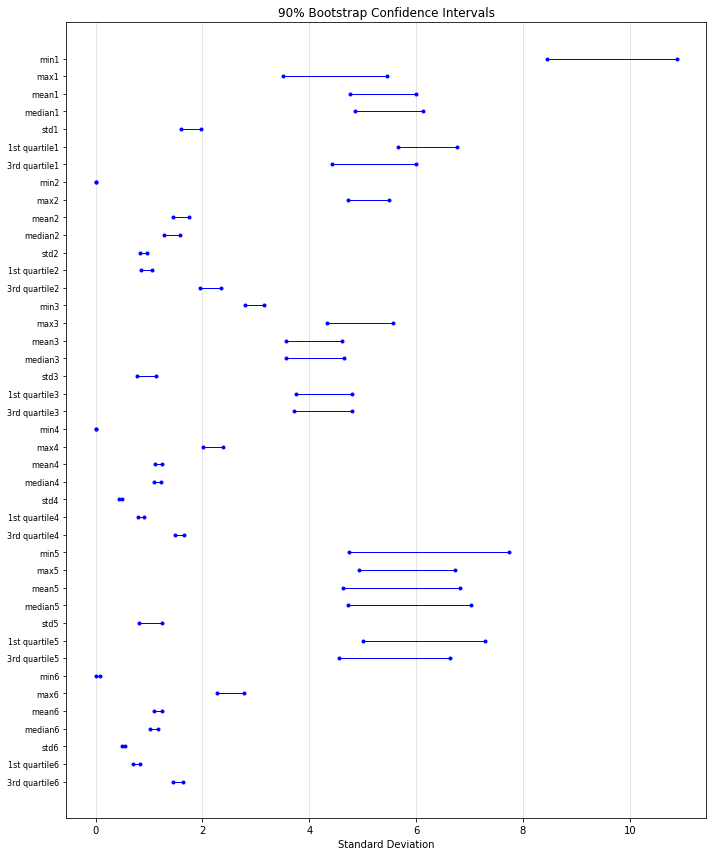

In [7]:
plt.figure(figsize=(10, 12))

for i in range(len(std_results)):
    plt.plot(
        [std_results["90% CI Lower"][i],
         std_results["90% CI Upper"][i]],
        [i, i],
        "o-",
        color="blue",
        linewidth=1,
        markersize=3
    )

plt.yticks(range(len(std_results)), std_results["Feature"], fontsize=8)
plt.gca().invert_yaxis()
plt.xlabel("Standard Deviation")
plt.title("90% Bootstrap Confidence Intervals")
plt.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

#### iv. Select Features

I selected the minimum, mean, and maximum. The minimum and maximum show the lowest and highest sensor readings, while the mean shows the average reading. These summarize the range and average level of the sensor data, which can help describe differences between activities. 

## 2. ISLR 3.7.4

### (a) Linear Train

The cubic regression should have a lower or equal training RSS because it's more flexible than the linear model and can fit the training data better.

### (b) Linear Test

The linear regression should have a lower test RSS because the true relationship between X and Y is linear. The cubic model may fit random noise in the training data, making its predictions less accurate on new data.

### (c) Not Linear Train

The cubic regression should have a lower or equal training RSS because it can capture curved patterns in the data that the linear model can't capture.

### (d) Not Linear Testing

There's not enough information, because if the true relationship is slightly nonlinear, the linear model may perform better. If the relationship has a stronger cubic pattern, the cubic model may be more accurate in giving predictions. 

## 3. ISLR 3.7.3 - Extra Practice 

## 3. ISLR 3.7.5 - Extra Practice 